# TP1 — Comptage des mots

## 1. Version Python séquentielle

### Objectif
Implémenter un algorithme permettant de compter le nombre d'occurrences de chaque mot dans un fichier texte.

Cette première méthode utilise un dictionnaire Python pour associer chaque mot à son nombre d'apparitions.

Je commence par un petit fichier afin de vérifier le fonctionnement de l'algorithme, avant de réaliser des tests sur des fichiers plus volumineux.

In [1]:

# Création d'un fichier de test
mots = ["chat", "chien", "chat", "oiseau", "chien", "chat"]

with open("mots.txt", "w", encoding="utf-8") as fichier:
    for mot in mots:
        fichier.write(mot + "\n")

print("Fichier mots.txt créé avec succès !")


Fichier mots.txt créé avec succès !


open("mots.txt", "w") crée un fichier en mode écriture.

for mot in mots parcourt les six éléments de la liste.

fichier.write(mot + "\n") écrit chaque mot sur une nouvelle ligne.

with ferme automatiquement le fichier après l'écriture.

In [2]:

def compter_occurrences(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}

    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


La méthode get(mot, 0) récupère le compteur actuel du mot ou renvoie zéro lorsque celui-ci n'existe pas encore.

In [3]:

# Exécution de l'algorithme
resultats = compter_occurrences("mots.txt")

# Affichage des résultats
for mot, nb in sorted(
    resultats.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{mot} : {nb}")

# Vérification automatique
assert resultats == {
    "chat": 3,
    "chien": 2,
    "oiseau": 1
}

print("Test réussi !")


chat : 3
chien : 2
oiseau : 1
Test réussi !


### Génération des jeux de données

Afin de comparer les performances des trois méthodes,
je génère plusieurs fichiers de tailles différentes.

Chaque ligne contient un seul mot choisi aléatoirement
dans un vocabulaire prédéfini.

Le fichier initial contient N lignes. Les fichiers suivants
sont obtenus en répétant ces N lignes m fois.

Cette méthode garantit que les fichiers conservent
la même distribution des mots.


In [4]:

from pathlib import Path
import random

N = 1000
multiplicateurs = [1, 10, 100]

vocabulaire = [
    "chat", "chien", "oiseau", "maison",
    "voiture", "arbre", "soleil", "livre"
]

# Créer un dossier pour les fichiers
dossier = Path("donnees")
dossier.mkdir(exist_ok=True)

# Générer les N lignes initiales
random.seed(42)

mots_base = [
    random.choice(vocabulaire)
    for _ in range(N)
]

# Création des fichiers par duplication
for m in multiplicateurs:

    chemin = dossier / f"mots_{m}xN.txt"

    with open(chemin, "w", encoding="utf-8") as f:
        for _ in range(m):
            for mot in mots_base:
                f.write(mot + "\n")

    print(f"{chemin} : {N * m} lignes")


donnees/mots_1xN.txt : 1000 lignes
donnees/mots_10xN.txt : 10000 lignes
donnees/mots_100xN.txt : 100000 lignes


In [5]:

# Vérification des fichiers générés

for m in multiplicateurs:
    chemin = dossier / f"mots_{m}xN.txt"

    with open(chemin, "r", encoding="utf-8") as f:
        nb_lignes = sum(1 for ligne in f)

    assert nb_lignes == N * m

    print(f"m = {m} : {nb_lignes} lignes - OK")


m = 1 : 1000 lignes - OK
m = 10 : 10000 lignes - OK
m = 100 : 100000 lignes - OK


### Mesure des performances de la version séquentielle

Je mesure le temps d'exécution de l'algorithme sur
plusieurs fichiers de tailles croissantes.

Chaque expérience est répétée 7 fois et je retiens
le temps médian.

Le temps mesuré comprend la lecture du fichier et
le comptage des occurrences, sans l'affichage des résultats.

Je vérifie également l'exactitude du comptage.

In [6]:

import time
from statistics import median

resultats_v1 = []

# Comptage du fichier de référence
reference = compter_occurrences(
    dossier / "mots_1xN.txt"
)

for m in multiplicateurs:
    chemin = dossier / f"mots_{m}xN.txt"
    mesures = []

    # Répéter le test 7 fois
    for _ in range(7):
        debut = time.perf_counter()

        compte = compter_occurrences(chemin)

        fin = time.perf_counter()
        mesures.append(fin - debut)

    # Vérifier l'exactitude du résultat
    attendu = {
        mot: nb * m
        for mot, nb in reference.items()
    }
    assert compte == attendu

    temps_median = median(mesures)

    # Conserver les résultats
    resultats_v1.append({
        "m": m,
        "lignes": N * m,
        "temps_s": temps_median
    })

    print(
        f"{N*m:>7} lignes | "
        f"Temps médian : {temps_median:.6f} s | "
        f"Résultat correct"
    )


   1000 lignes | Temps médian : 0.000383 s | Résultat correct
  10000 lignes | Temps médian : 0.003490 s | Résultat correct
 100000 lignes | Temps médian : 0.043296 s | Résultat correct


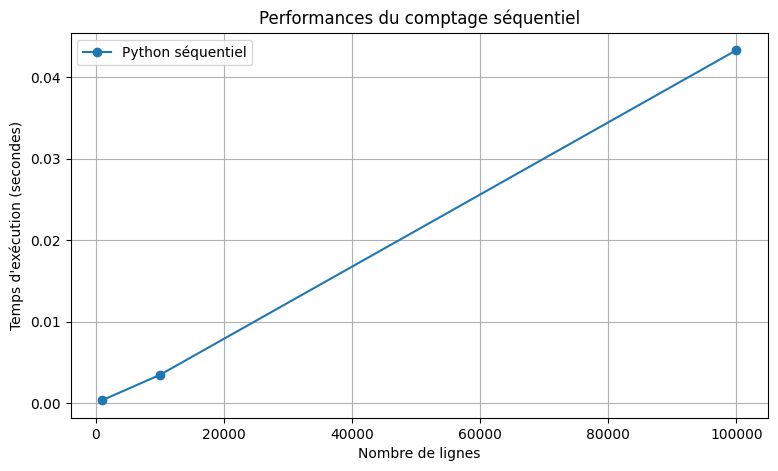

In [7]:

import matplotlib.pyplot as plt

tailles = [r["lignes"] for r in resultats_v1]
temps = [r["temps_s"] for r in resultats_v1]

plt.figure(figsize=(9, 5))

plt.plot(tailles, temps, marker="o", label="Python séquentiel")

plt.xlabel("Nombre de lignes")
plt.ylabel("Temps d'exécution (secondes)")
plt.title("Performances du comptage séquentiel")
plt.grid(True)
plt.legend()
plt.show()


### Analyse des performances de la version séquentielle

Les résultats montrent que le temps d'exécution augmente avec la taille du fichier. Pour 1 000 lignes, le traitement prend environ 0,0004 seconde, contre 0,0433 seconde pour 100 000 lignes.

Cette évolution est cohérente avec une complexité temporelle moyenne O(n), puisque l'algorithme parcourt les mots une seule fois pour mettre à jour leurs occurrences dans un dictionnaire.

Les écarts à une proportionnalité parfaite peuvent s'expliquer par les fluctuations de l'environnement Colab, la gestion de la mémoire et les opérations de lecture des fichiers.

Cette méthode constitue une référence pour les prochaines comparaisons avec le pseudo-MapReduce et Hadoop MapReduce.

## 2. Version Pseudo-MapReduce

### Objectif

Implémenter un programme de comptage des mots en reproduisant les trois phases du modèle MapReduce :

- **Map** : transformation des mots en paires (clé, valeur).
- **Shuffle** : regroupement des valeurs par clé.
- **Reduce** : agrégation des valeurs pour calculer les occurrences.

Cette implémentation fonctionne localement et ne réalise pas de traitement distribué.

In [8]:

from collections import defaultdict

# Phase 1 : MAP
def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]


# Phase 2 : SHUFFLE
def shuffle(mapped_data):
    grouped = defaultdict(list)

    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)

    return grouped


# Phase 3 : REDUCE
def reducer(grouped_data):
    reduced = {}

    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)

    return reduced


In [9]:

# Lire le fichier de test
with open("mots.txt", "r", encoding="utf-8") as f:
    lignes = f.readlines()

# Phase MAP
mapped = []

for ligne in lignes:
    mapped.extend(mapper(ligne))

print("MAP :", mapped)

# Phase SHUFFLE
grouped = shuffle(mapped)
print("\nSHUFFLE :", dict(grouped))

# Phase REDUCE
reduced = reducer(grouped)
print("\nREDUCE :", reduced)


MAP : [('chat', 1), ('chien', 1), ('chat', 1), ('oiseau', 1), ('chien', 1), ('chat', 1)]

SHUFFLE : {'chat': [1, 1, 1], 'chien': [1, 1], 'oiseau': [1]}

REDUCE : {'chat': 3, 'chien': 2, 'oiseau': 1}


In [10]:

def compter_occurrences_mapreduce(fichier):

    # MAP
    mapped = []

    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))

    # SHUFFLE
    grouped = shuffle(mapped)

    # REDUCE
    reduced = reducer(grouped)

    return reduced


# Test de la version 2
resultats_v2_test = compter_occurrences_mapreduce("mots.txt")

# Vérification avec la version 1
assert resultats_v2_test == resultats

print("Résultat :", resultats_v2_test)
print("Version 2 validée : mêmes résultats que la version 1 !")


Résultat : {'chat': 3, 'chien': 2, 'oiseau': 1}
Version 2 validée : mêmes résultats que la version 1 !


In [11]:

# Mesure des performances de la version 2

resultats_v2 = []

for m in multiplicateurs:
    chemin = dossier / f"mots_{m}xN.txt"
    mesures = []

    # Répéter 7 fois pour obtenir un temps médian
    for _ in range(7):

        debut = time.perf_counter()

        compte = compter_occurrences_mapreduce(chemin)

        fin = time.perf_counter()

        mesures.append(fin - debut)

    # Vérifier que le comptage est correct
    attendu = {
        mot: nb * m
        for mot, nb in reference.items()
    }

    assert compte == attendu

    temps_median = median(mesures)

    resultats_v2.append({
        "m": m,
        "lignes": N * m,
        "temps_s": temps_median
    })

    print(
        f"{N*m:>7} lignes | "
        f"Temps médian : {temps_median:.6f} s | "
        f"Résultat correct"
    )


   1000 lignes | Temps médian : 0.001162 s | Résultat correct
  10000 lignes | Temps médian : 0.013177 s | Résultat correct
 100000 lignes | Temps médian : 0.124828 s | Résultat correct


In [12]:

print(f"{'Lignes':>10} | {'Python (ms)':>14} | {'MapReduce (ms)':>16}")
print("-" * 46)

for v1, v2 in zip(resultats_v1, resultats_v2):

    assert v1["lignes"] == v2["lignes"]

    t1 = v1["temps_s"] * 1000
    t2 = v2["temps_s"] * 1000

    print(
        f"{v1['lignes']:>10} | "
        f"{t1:>14.3f} | "
        f"{t2:>16.3f}"
    )


    Lignes |    Python (ms) |   MapReduce (ms)
----------------------------------------------
      1000 |          0.383 |            1.162
     10000 |          3.490 |           13.177
    100000 |         43.296 |          124.828


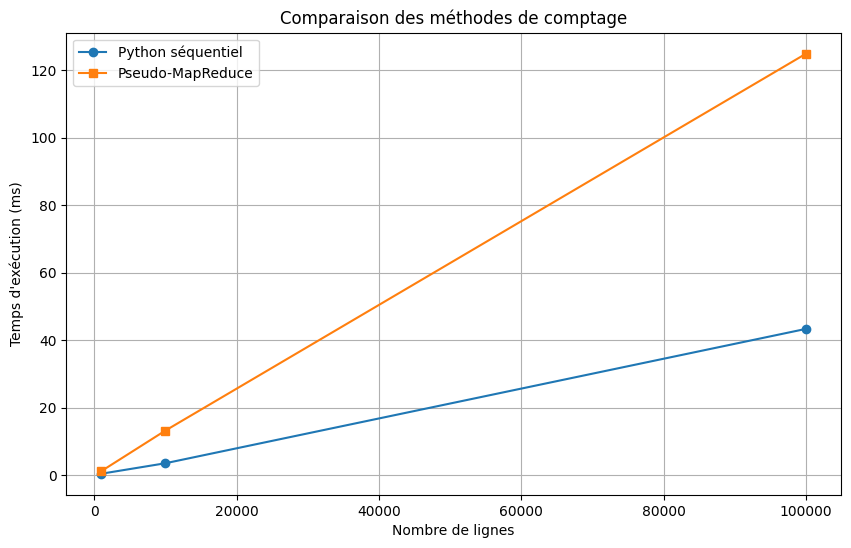

In [13]:

import matplotlib.pyplot as plt

# Tailles des fichiers
tailles = [r["lignes"] for r in resultats_v1]

# Temps en millisecondes
temps_v1 = [r["temps_s"] * 1000 for r in resultats_v1]
temps_v2 = [r["temps_s"] * 1000 for r in resultats_v2]

plt.figure(figsize=(10, 6))

plt.plot(
    tailles, temps_v1,
    marker="o",
    label="Python séquentiel"
)

plt.plot(
    tailles, temps_v2,
    marker="s",
    label="Pseudo-MapReduce"
)

plt.xlabel("Nombre de lignes")
plt.ylabel("Temps d'exécution (ms)")
plt.title("Comparaison des méthodes de comptage")
plt.grid(True)
plt.legend()
plt.show()


### Comparaison des performances : Python séquentiel et pseudo-MapReduce

Les résultats montrent que la version Python séquentielle est plus rapide que le pseudo-MapReduce pour les trois tailles de fichiers testées.

Pour 100 000 lignes, le temps d'exécution est de 43,296 ms pour Python séquentiel contre 124,828 ms pour le pseudo-MapReduce, soit environ 2,88 fois plus de temps.

Cette différence s'explique par les opérations supplémentaires de la méthode MapReduce : création des paires clé-valeur, regroupement des valeurs puis agrégation.

Les deux méthodes présentent une évolution compatible avec une complexité temporelle moyenne O(n), mais avec des coûts d'exécution différents.

Le pseudo-MapReduce présente surtout un intérêt pédagogique pour comprendre l'organisation des traitements distribués. Son exécution locale ne bénéficie pas des possibilités de parallélisation offertes par Hadoop.

## 3. Version Hadoop MapReduce

### 3.1. Environnement de travail

J'ai installé Hadoop sur mon ordinateur Windows en passant par WSL, avec Ubuntu 26.04 LTS. Cela me permet de travailler directement sous Linux sans avoir besoin d'installer une machine virtuelle supplémentaire.

J'ai configuré Hadoop en mode pseudo-distribué. Les différents services fonctionnent donc sur une seule machine, mais dans des processus Java séparés. Ce mode est suffisant pour comprendre le fonctionnement de HDFS, YARN et MapReduce.

Voici l'environnement que j'ai utilisé :

| Composant | Version |
|---|---|
| Système d'exploitation | Ubuntu 26.04 LTS (WSL) |
| Java | OpenJDK 11 |
| Hadoop | Apache Hadoop 3.4.0 |
| Système de stockage | HDFS |
| Gestionnaire de ressources | YARN |
| Traitement | Hadoop MapReduce |

Source : [Documentation officielle Hadoop — Single Node Cluster](https://hadoop.apache.org/docs/r3.4.0/hadoop-project-dist/hadoop-common/SingleCluster.html).

### 3.2. Installation de Java et Hadoop

J'ai commencé par installer Java, qui est nécessaire au fonctionnement de Hadoop. J'ai utilisé OpenJDK 11, une version compatible avec Hadoop 3.4.0.

Pour l'installation, j'ai exécuté les commandes suivantes dans mon terminal Ubuntu :

- `sudo apt update`
- `sudo apt install -y openjdk-11-jdk-headless openssh-server wget tar`

J'ai ensuite vérifié que Java fonctionnait avec `java -version`. Le terminal m'a bien retourné la version 11.

Pour Hadoop, j'ai récupéré l'archive de la version 3.4.0 depuis le site officiel Apache à l'aide de la commande :

`wget -c https://archive.apache.org/dist/hadoop/common/hadoop-3.4.0/hadoop-3.4.0.tar.gz`

Une fois le téléchargement terminé, j'ai extrait l'archive avec :

`tar -xzf hadoop-3.4.0.tar.gz`

J'ai ensuite configuré les variables d'environnement dans le fichier `~/.bashrc` pour pouvoir utiliser Hadoop depuis mon terminal :

- `JAVA_HOME=/usr/lib/jvm/java-11-openjdk-amd64`
- `HADOOP_HOME=$HOME/hadoop-3.4.0`
- `PATH=$HADOOP_HOME/bin:$HADOOP_HOME/sbin:$PATH`

J'ai également renseigné le chemin de Java dans le fichier `hadoop-env.sh`.

Pour terminer, j'ai exécuté `hadoop version`. La commande m'a retourné Hadoop 3.4.0, ce qui m'a permis de confirmer que l'installation était correcte.

Source : [Archives officielles Apache Hadoop 3.4.0](https://archive.apache.org/dist/hadoop/common/hadoop-3.4.0/).

### 3.3. Configuration de SSH

Avant de démarrer les services Hadoop, j'ai dû configurer SSH.

Même si Hadoop fonctionne sur une seule machine dans mon cas, certains scripts utilisent SSH pour démarrer les différents processus.

J'ai d'abord lancé le serveur avec `sudo service ssh start`, puis testé la connexion avec `ssh localhost`.

La connexion fonctionnait, mais elle demandait mon mot de passe. J'ai donc généré une paire de clés SSH et ajouté ma clé publique dans le fichier `~/.ssh/authorized_keys`.

J'ai ensuite testé la connexion automatique avec la commande :

`ssh -o BatchMode=yes localhost 'echo "SSH sans mot de passe : OK"'`

Le terminal a affiché le message attendu. Je pouvais donc me connecter en SSH sur ma propre machine sans saisir de mot de passe.

### 3.4. Configuration de HDFS

Après l'installation de Hadoop, je me suis occupé de HDFS, le système de fichiers utilisé pour stocker les données.

HDFS fonctionne principalement avec deux composants : le NameNode et le DataNode.

Le NameNode gère les informations sur les fichiers et leurs emplacements, tandis que le DataNode est chargé de stocker les blocs de données.

J'ai commencé par modifier le fichier `core-site.xml` afin d'indiquer l'adresse du NameNode et le dossier utilisé pour stocker les données de Hadoop.

J'ai défini les paramètres suivants :

| Paramètre | Valeur |
|---|---|
| `fs.defaultFS` | `hdfs://localhost:9000` |
| `hadoop.tmp.dir` | `/home/ibend/hadoop_data` |

Dans le fichier `hdfs-site.xml`, j'ai ensuite fixé `dfs.replication` à `1`.

Comme je travaille avec un seul DataNode, il n'est pas nécessaire de répliquer les blocs sur plusieurs machines.

Une fois les fichiers XML configurés, j'ai initialisé le NameNode avec :

`hdfs namenode -format`

Cette commande prépare le système de fichiers HDFS pour sa première utilisation. Le formatage s'est terminé correctement.

J'ai ensuite démarré les services avec `start-dfs.sh`.

Pour vérifier que les processus étaient actifs, j'ai utilisé la commande `jps`, qui m'a permis de retrouver le NameNode, le DataNode et le SecondaryNameNode.

J'ai également ouvert l'interface Web de HDFS depuis mon navigateur à l'adresse `http://localhost:9870`.

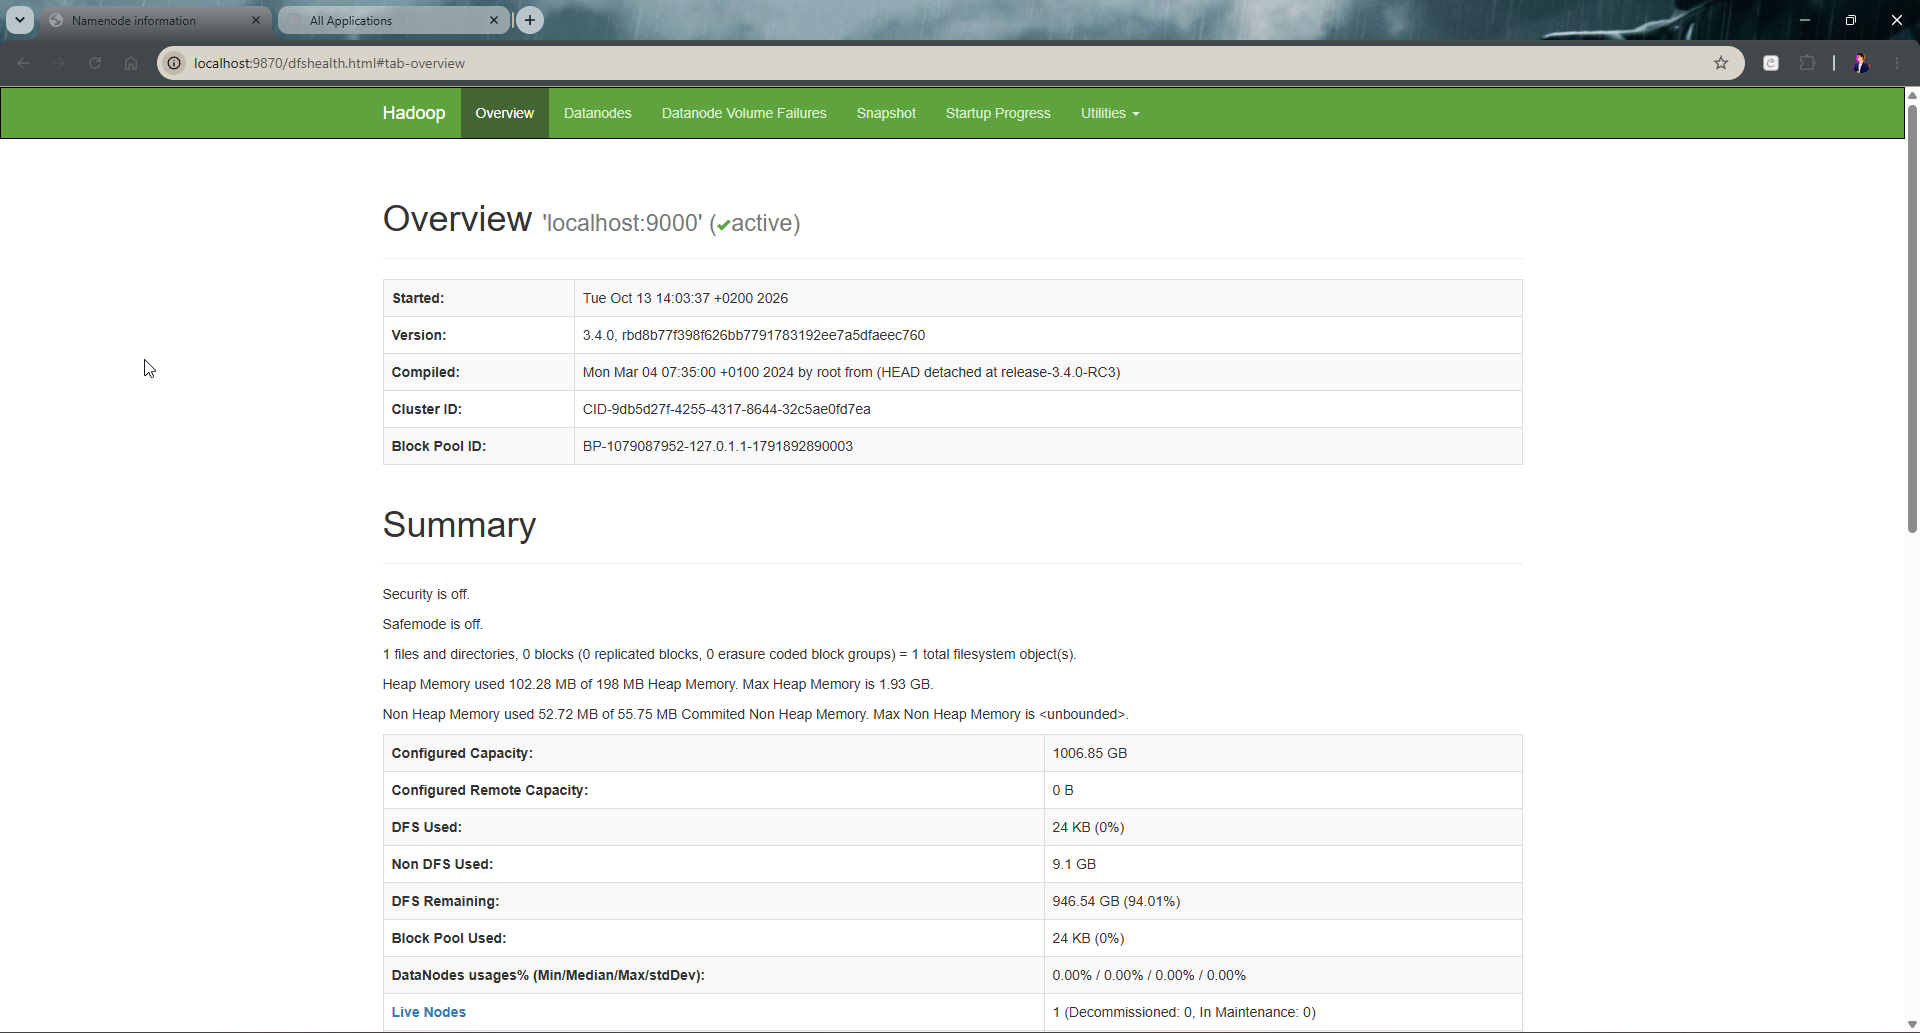

L'interface indiquait que le NameNode était actif et qu'un DataNode était connecté. Le Safe Mode était également désactivé, ce qui confirmait que HDFS était prêt à être utilisé.

Source : [Apache Hadoop — HDFS et configuration pseudo-distribuée](https://hadoop.apache.org/docs/r3.4.0/hadoop-project-dist/hadoop-common/SingleCluster.html).

### 3.5. Configuration de YARN

Une fois HDFS opérationnel, j'ai configuré YARN afin de pouvoir lancer mes traitements MapReduce.

YARN est chargé de gérer les ressources disponibles et d'organiser l'exécution des différentes applications Hadoop.

J'ai modifié deux fichiers de configuration.

Dans `mapred-site.xml`, j'ai défini `mapreduce.framework.name` avec la valeur `yarn`. Ce paramètre permet d'utiliser YARN pour l'exécution des jobs MapReduce.

J'ai également configuré `mapreduce.application.classpath` pour indiquer l'emplacement des bibliothèques MapReduce.

Dans `yarn-site.xml`, j'ai activé le service `mapreduce_shuffle`, utilisé pendant le transfert des données entre les phases Map et Reduce. J'ai aussi configuré les variables d'environnement nécessaires aux conteneurs YARN.

Après avoir vérifié mes fichiers XML, j'ai démarré YARN avec :

`start-yarn.sh`

J'ai ensuite exécuté `jps` pour vérifier que les processus ResourceManager et NodeManager étaient bien lancés.

Enfin, j'ai accédé à l'interface Web YARN à l'adresse `http://localhost:8088`.

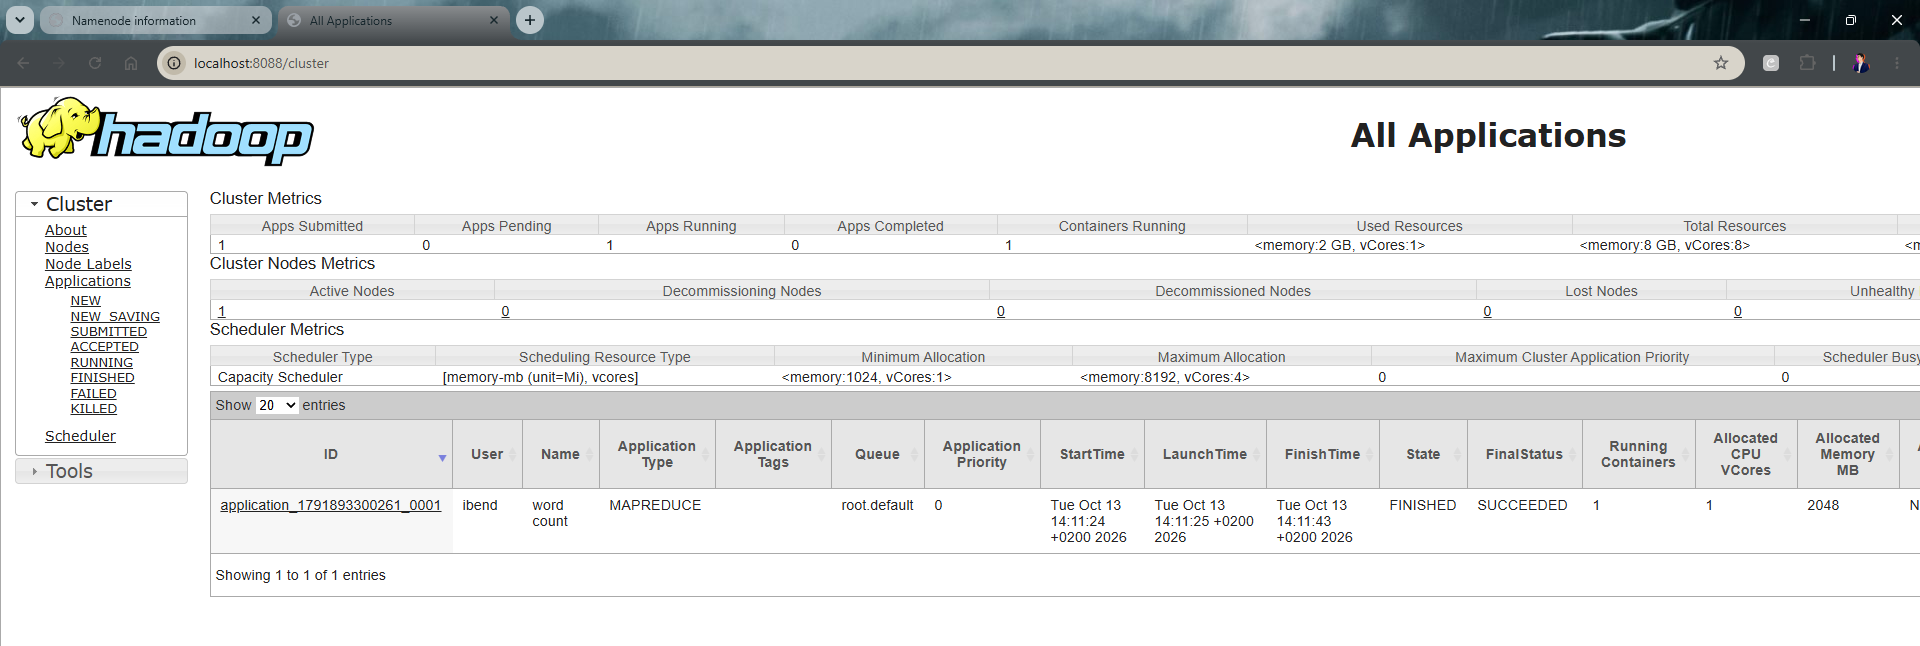

L'interface affichait un nœud actif, avec 8 Go de mémoire et 8 cœurs virtuels annoncés comme ressources disponibles. À ce stade, aucune application MapReduce n'avait encore été exécutée.

Source : [Apache Hadoop — YARN on a Single Node](https://hadoop.apache.org/docs/r3.4.0/hadoop-project-dist/hadoop-common/SingleCluster.html#YARN_on_a_Single_Node).

### 3.6. Préparation des fichiers dans HDFS

Une fois Hadoop configuré, j'ai repris les mêmes jeux de données que pour les deux premières versions du TP.

J'ai généré trois fichiers contenant respectivement 1 000, 10 000 et 100 000 lignes. Chaque ligne contient un mot choisi dans un vocabulaire de huit mots, avec la même graine aléatoire que dans mes tests Python.

Les fichiers ont d'abord été créés localement dans le dossier `~/TP_Comptage_Mots/donnees`.

J'ai ensuite créé un répertoire dans HDFS avec :

`hdfs dfs -mkdir -p /user/ibend/wordcount/input`

Puis j'ai transféré les fichiers avec :

`hdfs dfs -put -f ~/TP_Comptage_Mots/donnees/*.txt /user/ibend/wordcount/input/`

La commande `hdfs dfs -ls` m'a permis de vérifier que les trois fichiers étaient présents dans HDFS.

J'ai également contrôlé le nombre de lignes du plus grand fichier. Le résultat était bien de 100 000 lignes.

### 3.7. Exécution de WordCount avec Hadoop

Pour le comptage des mots, j'ai utilisé le programme WordCount fourni directement avec Hadoop dans le fichier `hadoop-mapreduce-examples-3.4.0.jar`.

Ce programme reprend les étapes Map, Shuffle et Reduce étudiées précédemment, mais cette fois avec le framework Hadoop et une exécution gérée par YARN.

J'ai commencé par tester le fichier de 1 000 lignes. J'ai utilisé la commande `hadoop jar` en précisant le programme `wordcount`, le fichier d'entrée dans HDFS et un répertoire de sortie.

Pour lancer le programme WordCount sur mon premier fichier de 1 000 lignes, j'ai utilisé la commande suivante dans mon terminal WSL :

```bash
time hadoop jar \
"$HADOOP_HOME/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.0.jar" \
wordcount \
/user/ibend/wordcount/input/mots_1xN.txt \
/user/ibend/wordcount/output_1xN
```

Cette commande permet de lancer WordCount sur le fichier présent dans HDFS et d'enregistrer les résultats dans un nouveau répertoire. J'ai également utilisé `time` pour mesurer la durée totale du traitement.

Pour les fichiers de 10 000 et 100 000 lignes, j'ai repris la même commande en adaptant les chemins d'entrée et de sortie.

Le premier traitement s'est terminé en **23,566 secondes**.

J'ai ensuite consulté les résultats avec `hdfs dfs -cat`. Le fichier `part-r-00000` contenait les huit mots distincts et leurs nombres d'occurrences.

J'ai vérifié que la somme des occurrences était bien égale à 1 000.

J'ai répété l'opération avec les fichiers de 10 000 et 100 000 lignes. Les deux traitements se sont également terminés correctement, avec des sommes d'occurrences correspondant aux nombres de lignes attendus.

Pour comparer les performances de manière plus fiable, j'ai ensuite automatisé les mesures à l'aide d'un script Bash. Chaque taille de fichier a été testée trois fois supplémentaires, avec un répertoire de sortie différent pour chaque exécution.

J'ai enregistré les durées obtenues dans un fichier CSV afin de pouvoir calculer les temps médians et les comparer aux résultats Python.

Ces tests m'ont permis de constater que Hadoop présente un temps de lancement important sur de petits fichiers. Contrairement à la version séquentielle, le traitement nécessite aussi la gestion des ressources YARN, le démarrage des tâches et les échanges avec HDFS.

L'objectif de cette expérience n'est donc pas de démontrer que Hadoop est toujours plus rapide, mais de comprendre son fonctionnement et de voir comment son coût d'exécution évolue avec la taille des données.

### Sources

- [Apache Hadoop 3.4.0 — Single Node Cluster](https://hadoop.apache.org/docs/r3.4.0/hadoop-project-dist/hadoop-common/SingleCluster.html)
- [Apache Hadoop 3.4.0 — Cluster Setup](https://hadoop.apache.org/docs/r3.4.0/hadoop-project-dist/hadoop-common/ClusterSetup.html)
- [Apache Hadoop — Archives officielles](https://archive.apache.org/dist/hadoop/common/hadoop-3.4.0/)
- [Apache Hadoop — Compatibilité Java](https://cwiki.apache.org/confluence/spaces/HADOOP/pages/100827883/Hadoop+Java+Versions)

## 4. Comparaison des performances

### 4.1. Méthodologie

Pour comparer les trois méthodes, j'ai utilisé les mêmes fichiers de 1 000, 10 000 et 100 000 lignes.

J'ai effectué les mesures sur mon ordinateur avec Ubuntu WSL afin d'éviter de comparer des temps provenant de machines différentes.

Pour les versions Python séquentielle et pseudo-MapReduce, j'ai réalisé 7 exécutions par fichier. Pour Hadoop, j'ai effectué 3 exécutions supplémentaires par taille après les premiers tests de fonctionnement.

J'ai choisi de retenir la médiane des temps, car elle permet de limiter l'influence des variations ponctuelles pendant les exécutions.

Les temps Python comprennent la lecture et le comptage des mots. Pour Hadoop, j'ai mesuré la durée complète du job, y compris son lancement avec YARN. La génération des fichiers et leur transfert initial dans HDFS ne sont pas pris en compte.

Cette comparaison permet donc d'étudier les coûts d'exécution de chaque méthode, même si leur fonctionnement interne est différent.

In [17]:

import pandas as pd
from statistics import median

# Tailles des fichiers
tailles = [1000, 10000, 100000]

# Mesures Python obtenues sur WSL (en ms)
python_simple = [0.115, 1.109, 12.442]
pseudo_mapreduce = [0.342, 3.234, 36.333]

# Mesures Hadoop obtenues sur WSL (en s)
hadoop_mesures = [
    [21.25, 19.19, 18.05],
    [18.92, 19.38, 21.52],
    [26.79, 19.06, 26.27]
]

# Calcul des médianes Hadoop
hadoop_medianes = [
    median(mesures) * 1000
    for mesures in hadoop_mesures
]

# Création du tableau
comparaison = pd.DataFrame({
    "Nombre de lignes": tailles,
    "Python simple (ms)": python_simple,
    "Pseudo-MapReduce (ms)": pseudo_mapreduce,
    "Hadoop (ms)": hadoop_medianes
})

display(comparaison)


,Nombre de lignes,Python simple (ms),Pseudo-MapReduce (ms),Hadoop (ms)
0,1000,0.115,0.342,19190.0
1,10000,1.109,3.234,19380.0
2,100000,12.442,36.333,26270.0


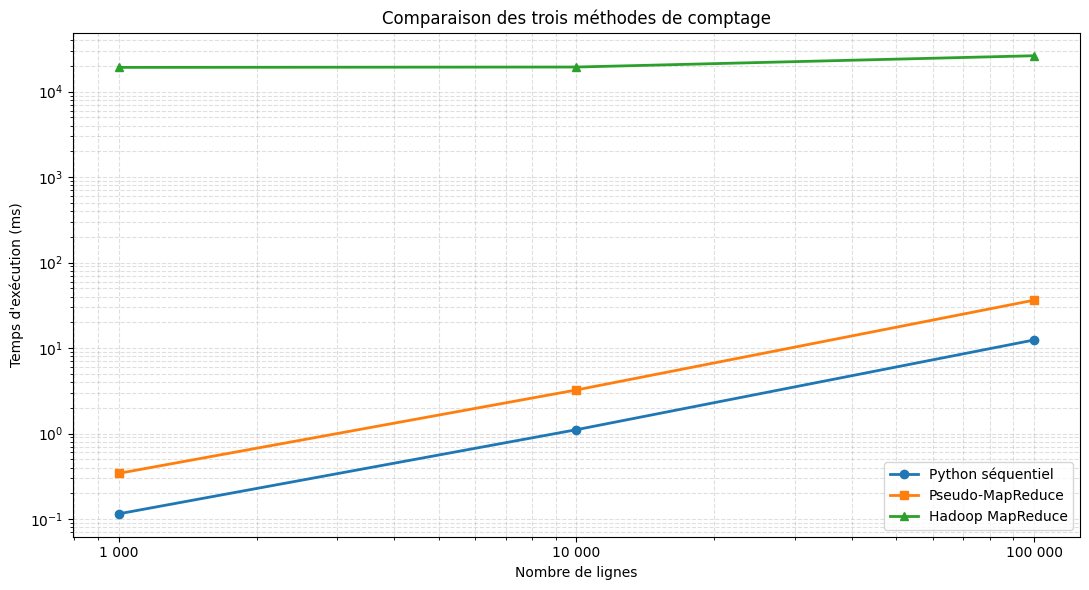

In [18]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

# Version 1 : Python simple
plt.plot(
    tailles,
    python_simple,
    marker="o",
    linewidth=2,
    label="Python séquentiel"
)

# Version 2 : Pseudo-MapReduce
plt.plot(
    tailles,
    pseudo_mapreduce,
    marker="s",
    linewidth=2,
    label="Pseudo-MapReduce"
)

# Version 3 : Hadoop
plt.plot(
    tailles,
    hadoop_medianes,
    marker="^",
    linewidth=2,
    label="Hadoop MapReduce"
)

# Échelles logarithmiques
plt.xscale("log")
plt.yscale("log")

plt.xticks(
    tailles,
    ["1 000", "10 000", "100 000"]
)

plt.xlabel("Nombre de lignes")
plt.ylabel("Temps d'exécution (ms)")
plt.title("Comparaison des trois méthodes de comptage")

plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

plt.show()


### 4.2. Représentation graphique des résultats

J'ai représenté les temps d'exécution des trois méthodes en fonction du nombre de lignes.

J'ai utilisé une échelle logarithmique afin de pouvoir afficher les trois courbes sur un même graphique, car les différences de temps entre Python et Hadoop sont importantes.

Les deux versions Python présentent une augmentation du temps d'exécution lorsque le nombre de lignes augmente. En revanche, la courbe Hadoop évolue beaucoup moins sur les tailles étudiées.

Je remarque également que le pseudo-MapReduce reste plus lent que la version séquentielle, même si les deux méthodes suivent une évolution assez similaire.

Pour Hadoop, les coûts liés au démarrage et à la gestion du job semblent représenter une grande partie du temps total. Sur les petits fichiers utilisés dans ce TP, le traitement distribué ne présente donc pas d'avantage en matière de temps d'exécution.

### 4.3. Analyse des performances

Les résultats montrent des différences assez importantes entre les trois méthodes.

La version Python séquentielle est la plus rapide sur l'ensemble des fichiers testés. Pour 1 000 lignes, elle prend seulement 0,115 ms, contre 12,442 ms pour 100 000 lignes. Le temps d'exécution augmente donc avec le nombre de mots à traiter, ce qui correspond à ce que j'attendais pour un algorithme qui parcourt les données une seule fois.

Le pseudo-MapReduce suit globalement la même évolution, mais reste environ trois fois plus lent. Cette différence vient principalement des étapes supplémentaires nécessaires au traitement. Contrairement à la première version, je dois créer des paires clé-valeur, les regrouper dans des listes, puis additionner leurs valeurs.

Ces opérations demandent davantage de mémoire et de traitements intermédiaires, sans apporter de gain de performance puisque cette version ne fonctionne pas en parallèle.

Pour Hadoop, les résultats sont différents. Le temps médian passe de 19,19 secondes pour 1 000 lignes à 26,27 secondes pour 100 000 lignes. L'augmentation reste relativement faible par rapport à la multiplication du volume de données.

Cela s'explique notamment par le temps nécessaire au lancement du job, à l'allocation des ressources par YARN et à l'exécution des tâches MapReduce. Pour des fichiers aussi petits, ces opérations prennent beaucoup plus de temps que le comptage lui-même.

J'ai également remarqué que les temps Hadoop variaient d'une exécution à l'autre, même lorsque la taille du fichier ne changeait pas. C'est pour cette raison que j'ai réalisé plusieurs essais et retenu les temps médians.

### 4.4. Complexité et limites de la comparaison

D'un point de vue algorithmique, les deux versions Python présentent une complexité temporelle moyenne de O(n), avec n le nombre de mots à traiter.

La version séquentielle parcourt chaque mot et met à jour un dictionnaire. Le pseudo-MapReduce parcourt également les mots, mais utilise des structures intermédiaires supplémentaires pendant les phases Map et Shuffle.

Pour Hadoop, le fonctionnement est plus complexe. Le traitement repose sur plusieurs tâches et nécessite des échanges avec HDFS et YARN. Son temps d'exécution ne dépend donc pas uniquement du nombre de mots.

Il faut aussi prendre en compte les limites de mon environnement. Même si Hadoop utilise une architecture prévue pour le traitement distribué, je l'ai configuré en mode pseudo-distribué sur un seul ordinateur. Je ne bénéficie donc pas du parallélisme entre plusieurs machines.

De plus, le plus grand fichier testé contient seulement 100 000 lignes, soit environ 654 Ko. Ce volume reste très faible pour Hadoop.

Mes résultats montrent donc que Python est plus adapté aux petits fichiers dans les conditions de ce TP. En revanche, je ne peux pas déterminer à partir de ces tests à quelle taille Hadoop pourrait devenir plus intéressant.

Pour étudier davantage cet aspect, il faudrait utiliser des fichiers beaucoup plus volumineux et réaliser les tests sur un véritable cluster de plusieurs machines.

## 5. Conclusion

Ce TP m'a permis de comparer trois façons de réaliser un comptage de mots : une version Python séquentielle, une simulation MapReduce en Python et une version utilisant Apache Hadoop.

J'ai commencé par implémenter les deux premières méthodes, puis j'ai installé et configuré Hadoop sur mon ordinateur avec WSL. J'ai notamment pu découvrir le fonctionnement de HDFS pour le stockage des données et de YARN pour la gestion des traitements.

Les tests ont montré que les trois méthodes produisaient les mêmes résultats, mais avec des temps d'exécution très différents.

Sur les fichiers utilisés, la version Python séquentielle reste la plus efficace. Le pseudo-MapReduce est un peu plus lent en raison des opérations intermédiaires, tandis que Hadoop présente un temps de lancement beaucoup plus important.

Ce que je retiens surtout, c'est que l'utilisation d'un framework distribué n'améliore pas automatiquement les performances. Son intérêt dépend du volume de données, des ressources disponibles et de la manière dont les traitements sont répartis.

Avec les tailles testées et mon installation sur un seul nœud, Hadoop n'apporte pas de gain de temps. En revanche, ce TP m'a permis de mieux comprendre les différentes étapes de MapReduce et les contraintes liées à la mise en place d'un environnement Big Data.

Pour aller plus loin, il serait intéressant de refaire cette comparaison sur plusieurs gigaoctets de données et avec un cluster de plusieurs machines, afin d'observer les gains éventuels liés à la distribution du traitement.

## 6. Annexes
### 6.1. Script de benchmark Python

Ce script m'a permis de mesurer les performances
des versions Python séquentielle et pseudo-MapReduce
sur mon environnement WSL.

```python
import time
from pathlib import Path
from statistics import median
from collections import defaultdict

dossier = Path.home() / "TP_Comptage_Mots" / "donnees"

# Version 1 : Python séquentiel
def compter_simple(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


# Version 2 : Pseudo-MapReduce
def mapper(ligne):
    return [(mot, 1) for mot in ligne.strip().split()]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    return {
        mot: sum(valeurs)
        for mot, valeurs in grouped_data.items()
    }

def compter_mapreduce(fichier):
    mapped = []

    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))

    return reducer(shuffle(mapped))


# Mesures de performance
for m in [1, 10, 100]:
    fichier = dossier / f"mots_{m}xN.txt"

    resultats = []

    for fonction in [compter_simple, compter_mapreduce]:
        mesures = []

        for _ in range(7):
            debut = time.perf_counter()
            compte = fonction(fichier)
            fin = time.perf_counter()

            mesures.append(fin - debut)

        assert sum(compte.values()) == 1000 * m
        resultats.append((median(mesures) * 1000, compte))

    assert resultats[0][1] == resultats[1][1]

    print(
        f"{1000*m:>6} lignes | "
        f"Python : {resultats[0][0]:.3f} ms | "
        f"MapReduce : {resultats[1][0]:.3f} ms"
    )
```

### 6.2. Script de benchmark Hadoop

Ce script Bash m'a permis d'automatiser les tests
Hadoop sur les trois tailles de fichiers.

Chaque test a été exécuté trois fois, avec un
répertoire de sortie différent. Les temps ont
été enregistrés dans hadoop_mesures.csv.

```bash
#!/bin/bash
set -e

JAR="$HADOOP_HOME/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.0.jar"
BASE="/user/ibend/wordcount"
RUN_ID=$(date +%Y%m%d_%H%M%S)

echo "lignes,essai,temps_s" > hadoop_mesures.csv

for m in 1 10 100; do
    for essai in 1 2 3; do

        entree="$BASE/input/mots_${m}xN.txt"
        sortie="$BASE/bench_${RUN_ID}_${m}_${essai}"

        echo "Test Hadoop : $((1000*m)) lignes - Essai $essai"

        /usr/bin/time -f "%e" \
            -o /tmp/hadoop_chrono.txt \
            hadoop jar "$JAR" wordcount "$entree" "$sortie" \
            > "hadoop_${m}_${essai}.log" 2>&1

        hdfs dfs -test -e "$sortie/_SUCCESS"

        temps=$(cat /tmp/hadoop_chrono.txt)

        echo "$((1000*m)),$essai,$temps" \
            | tee -a hadoop_mesures.csv

    done
done

echo "Mesures Hadoop terminées."
```